# Notebook 04 - Decision engine: AHP + entropy weights, TOPSIS ranking, MILP order split

**PharmaShield GCC** - Group 3, AI in Operations, SP Jain Dubai. Academic prototype for a hypothetical UAE GPO.

| Item | Value |
|---|---|
| Build steps covered | Build step 7 - Hybrid TOPSIS ranking (Q1, Q5); Build step 8 - Dual-source order split, a mixed-integer linear program (MILP) (Q5, Q7) |
| Inputs | data/processed/scoring_panel_carboplatin.csv (notebook 02), data/processed/model_outputs_carboplatin.csv (notebook 03) |
| Outputs | data/processed/suppliers_matrix.csv (locked schema plus agreed extra columns), outputs/topsis_ranking_carboplatin_<mode>.csv, outputs/lp_allocation_carboplatin_<mode>.csv, web/data/*.json, figures/fig_12 to fig_15 |
| Modes | Normal, Crisis (Hormuz and Gulf airspace shock), Cost focus |

## 1. Objective

**Section intro.** This notebook turns the evidence into a decision a category manager can approve:
1. Build the five criteria C1 to C5 on a 0 to 1, lower-is-better scale for the 11 qualified makers.
2. Weight them: 50% board judgement (AHP, one pairwise matrix per mode, consistency ratio below 0.10) and 50% data (Shannon entropy), applied only where the data is real (override 7). The final blended weights are shown for every mode (override 9).
3. Rank the makers with TOPSIS in each mode.
4. Split a monthly order of 10,000 vials with a MILP (PuLP + CBC). Binary variables select suppliers, enforce dual sourcing, cap the primary at 70% and allow at most 2 probation trials (override 5).
5. Test how sensitive the split is to lambda, the board's price of risk, and how stable the ranking is to weight changes.

In [1]:
import sys, json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[0]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.common import PROCESSED, OUTPUTS, RANDOM_STATE, PALETTE, style, save_fig, shape
from src.mcdm import CRITERIA, ahp, entropy_weights, blend_weights, topsis, allocate_milp
from src import export

style()
rng = np.random.default_rng(RANDOM_STATE)
SKU_ID = "CARBOPLATIN_INJ_10MG_ML"
DEMAND = 10_000   # ASSUMPTION A11: monthly carboplatin demand of the GPO, in 45 mL vials
LAMBDA = 1.0      # override 5: board price of risk in the MILP objective, default 1.0
MODES = ["normal", "crisis", "cost"]
print("Demand", DEMAND, "vials | lambda", LAMBDA, "| modes", MODES)

Demand 10000 vials | lambda 1.0 | modes ['normal', 'crisis', 'cost']


**Section summary.** The two scenario inputs that drive the order split, demand and lambda, are fixed in one place and labelled as assumptions.

## 2. Exploratory data analysis

**Section intro.** We join the panel and the model outputs and look at the raw inputs per maker, including how much evidence stands behind each one.

In [2]:
panel = pd.read_csv(PROCESSED / "scoring_panel_carboplatin.csv", index_col="manufacturer_id")
models = pd.read_csv(PROCESSED / "model_outputs_carboplatin.csv", index_col="manufacturer_id")
shape("Panel", panel)
shape("Model outputs", models)
d = panel.join(models)
shape("Joined decision inputs", d)
d[["manufacturing_country", "is_probation", "c1_imputed", "landed_cost_per_vial_usd", "C2_delivery_risk", "C3_price_integrity", "c3_status",
   "inspections_5yr", "oai_count_5yr", "class_i_ii_5yr", "nlp_citations_5yr", "nlp_severity", "active_fda_shortage", "c5_normal"]].round(4)

Panel: 11 rows x 30 columns
Model outputs: 11 rows x 12 columns
Joined decision inputs: 11 rows x 42 columns


,manufacturing_country,is_probation,c1_imputed,landed_cost_per_vial_usd,C2_delivery_risk,C3_price_integrity,c3_status,inspections_5yr,oai_count_5yr,class_i_ii_5yr,nlp_citations_5yr,nlp_severity,active_fda_shortage,c5_normal
manufacturer_id,,,,,,,,,,,,,,
AVYXA,United States,True,True,189.9276,0.0159,0.0516,no invoice history,0,0,0,0,0.0000,True,0.228
ACCORD,India,False,False,122.3758,0.0449,0.0516,no invoice history,3,2,101,11,0.7570,True,0.272
APOTEX,Canada,True,False,329.8807,0.0369,0.0516,no invoice history,14,1,18,11,0.8492,False,0.190
BPI,India,True,True,188.6194,0.0449,0.0516,no invoice history,10,0,0,18,0.6866,True,0.272
EUGIA,India,False,False,217.8856,0.0919,0.0464,scored from SCMS invoice lines,7,4,18,27,0.8241,True,0.272
FRESENIUS,United States,False,False,160.4585,0.0159,0.0516,no invoice history,8,2,26,14,0.8496,True,0.228
GLAND,India,True,True,188.6194,0.0335,0.0516,invoice lines outside modelled groups,6,0,0,3,0.9198,False,0.272
HOSPIRA,United States,False,False,235.5813,0.0159,0.0516,no invoice history,5,0,0,3,0.8301,True,0.228
NATCO,India,True,True,188.6194,0.0449,0.0516,no invoice history,5,0,2,7,0.9300,True,0.272


**Business interpretation.** The 11 makers differ a lot in how much evidence stands behind them. Eugia has 7 inspections in 5 years, recalls, 27 citations and 3,283 SCMS lines; AVYXA has no inspection, no citation, no recall and no Medicaid price. A ranking that read missing evidence as a clean record would push the least-known maker to the top, so the next step treats missing evidence as neutral.

**Section summary.** Evidence is uneven. Some makers have dozens of inspections, recalls and citations, and others have none. The next section makes sure that missing evidence is treated as neutral, never as a clean record.

## 3. Preprocessing: build C1 to C5

**Section intro.** All five criteria are lower-is-better and lie between 0 and 1.
- **C1 landed cost** = min-max normalised landed cost per vial (0 = cheapest maker, 1 = most expensive).
- **C2 delivery risk** = prior-corrected XGBoost probability of a late shipment (notebook 03).
- **C3 price integrity** = share of SCMS invoice lines flagged by the Isolation Forest; makers with no invoice history receive the neutral population rate (notebook 03).
- **C4 compliance risk** = min(1, 0.30 x any OAI in 5 years + 0.10 x any VAI in 5 years + 0.20 x min(1, Class I/II recalls in 5 years / 2) + 0.20 x NLP citation severity + 0.20 x active US shortage). This is the plan's formula, with one change: the plan's contract-risk term is replaced by the active-shortage flag, because the only contracts available are synthetic (decision D9). **Neutral-evidence rule (assumption A31):** a maker with no FDA inspection in 5 years receives the panel median of the inspection term, and a maker whose inspections produced no posted citations receives the panel median NLP severity. A zero would wrongly reward missing data.
- **C5 route exposure** = notebook 02 value; Normal and Cost focus use StressFactor 1.0, Crisis uses 1.5.

In [3]:
shape("Before criteria construction", d)
lc = d["landed_cost_per_vial_usd"]
d["C1"] = (lc - lc.min()) / (lc.max() - lc.min())
d["C2"] = d["C2_delivery_risk"]
d["C3"] = d["C3_price_integrity"]

has_inspection = d["inspections_5yr"] > 0
insp_term_raw = 0.30 * (d["oai_count_5yr"] > 0) + 0.10 * (d["vai_count_5yr"] > 0)
insp_term = insp_term_raw.where(has_inspection, insp_term_raw[has_inspection].median())
citations_expected = (d["vai_count_5yr"] + d["oai_count_5yr"]) > 0
nlp_observed = (d["nlp_citations_5yr"] > 0) | (has_inspection & ~citations_expected)
nlp_term = d["nlp_severity"].where(nlp_observed, d.loc[nlp_observed, "nlp_severity"].median())
recall_term = np.minimum(1.0, d["class_i_ii_5yr"] / 2)
shortage_term = d["active_fda_shortage"].astype(float)
d["C4"] = np.minimum(1.0, insp_term + 0.20 * recall_term + 0.20 * nlp_term + 0.20 * shortage_term)
d["C4_without_neutral_rule"] = np.minimum(1.0, insp_term_raw + 0.20 * recall_term + 0.20 * d["nlp_severity"] + 0.20 * shortage_term)
d["c4_evidence_status"] = np.select([~has_inspection, ~nlp_observed], ["no FDA inspection in 5 years: neutral inspection and NLP terms",
                                     "inspected, citations not posted: neutral NLP term"], "observed")
d["C5_normal"], d["C5_crisis"] = d["c5_normal"], d["c5_crisis"]
shape("After criteria construction", d)
print(f"Neutral inspection term (panel median): {insp_term_raw[has_inspection].median():.3f} | neutral NLP severity: {d.loc[nlp_observed, 'nlp_severity'].median():.3f}")
d[["C1", "C2", "C3", "C4", "C4_without_neutral_rule", "C5_normal", "C5_crisis", "c4_evidence_status"]].round(4)

Before criteria construction: 11 rows x 42 columns
After criteria construction: 11 rows x 50 columns
Neutral inspection term (panel median): 0.100 | neutral NLP severity: 0.840


,C1,C2,C3,C4,C4_without_neutral_rule,C5_normal,C5_crisis,c4_evidence_status
manufacturer_id,,,,,,,,
AVYXA,0.3255,0.0159,0.0516,0.4679,0.2000,0.228,0.24,no FDA inspection in 5 years: neutral inspection and NLP terms
ACCORD,0.0000,0.0449,0.0516,0.8514,0.8514,0.272,0.32,observed
APOTEX,1.0000,0.0369,0.0516,0.7698,0.7698,0.190,0.20,observed
BPI,0.3192,0.0449,0.0516,0.4373,0.4373,0.272,0.32,observed
EUGIA,0.4603,0.0919,0.0464,0.9648,0.9648,0.272,0.32,observed
FRESENIUS,0.1835,0.0159,0.0516,0.9699,0.9699,0.228,0.24,observed
GLAND,0.3192,0.0335,0.0516,0.2840,0.2840,0.272,0.32,observed
HOSPIRA,0.5456,0.0159,0.0516,0.4660,0.4660,0.228,0.24,observed
NATCO,0.3192,0.0449,0.0516,0.6860,0.6860,0.272,0.32,observed


**Business interpretation.** The neutral-evidence rule changes one maker materially: AVYXA's C4 rises from 0.200 (which would have looked like the cleanest record in the panel) to 0.468, close to the panel middle. Teva Parenteral also has no inspection in 5 years and receives the neutral terms (C4 0.668, driven mainly by 46 Class I/II recalls), and Teyro receives a neutral NLP term because its 2025 inspection has no posted citations yet. Compliance risk is highest for Fresenius Kabi (0.970), Eugia (0.965) and Accord (0.851), and lowest for Teyro (0.268) and Gland (0.284).

In [4]:
TIER = {"tier": 1, "basis": "WHO Model List of Essential Medicines, cytotoxic medicines (carboplatin)", "primary_cap": 0.70,
        "min_established_makers": 2, "trial_share": [0.05, 0.15]}
CAPACITY_ESTABLISHED, CAPACITY_PROBATION, SHORTAGE_FACTOR = 10_000, 2_000, 0.8  # ASSUMPTIONS A27, A28
d["monthly_capacity_units"] = (np.where(d["is_probation"], CAPACITY_PROBATION, CAPACITY_ESTABLISHED)
                               * np.where(d["active_fda_shortage"], SHORTAGE_FACTOR, 1.0)).astype(int)
print("Tier rules:", TIER)
d[["is_probation", "trial_gate_pass", "active_fda_shortage", "monthly_capacity_units"]]

Tier rules: {'tier': 1, 'basis': 'WHO Model List of Essential Medicines, cytotoxic medicines (carboplatin)', 'primary_cap': 0.7, 'min_established_makers': 2, 'trial_share': [0.05, 0.15]}


,is_probation,trial_gate_pass,active_fda_shortage,monthly_capacity_units
manufacturer_id,,,,
AVYXA,True,True,True,1600
ACCORD,False,False,True,8000
APOTEX,True,False,False,2000
BPI,True,True,True,1600
EUGIA,False,False,True,8000
FRESENIUS,False,False,True,8000
GLAND,True,True,False,2000
HOSPIRA,False,True,True,8000
NATCO,True,True,True,1600


**Business interpretation.** Carboplatin is Tier 1 (life-critical oncology), so the split must use at least 2 established makers, cap the primary at 70% and keep trial volume between 5% and 15%. Capacities are scenario values: 10,000 vials a month for an established maker and 2,000 for a probation maker, cut by 20% when the maker has a current US shortage record. That cut applies to 8 of the 11 makers.

**Section summary.** The decision matrix is complete: 11 makers by 5 criteria, plus a Crisis version of C5, with every imputed or neutral value labelled.

## 4. Modelling

### 4.1 AHP: one pairwise matrix per mode (assumption A10)

**Section intro.** The team, role-playing the GPO board, compared criteria in pairs on Saaty's 1 to 9 scale (for example, "delivery risk is 3 times as important as cost" in Normal mode). The principal eigenvector gives the weights; the consistency ratio (CR) must be below 0.10. The plan's target weights for Tier 1 are shown alongside. The Crisis target sets cost to 0.00, which AHP cannot produce, so a 0.05 floor applies (Phase 0 fix F7).

In [5]:
AHP_MATRICES = {
    "normal": [[1, 1/3, 2, 1/3, 1/2], [3, 1, 6, 1, 1], [1/2, 1/6, 1, 1/6, 1/5], [3, 1, 6, 1, 1], [2, 1, 5, 1, 1]],
    "crisis": [[1, 1/6, 1, 1/6, 1/7], [6, 1, 6, 1, 1], [1, 1/6, 1, 1/6, 1/7], [6, 1, 6, 1, 1], [7, 1, 7, 1, 1]],
    "cost":   [[1, 1/2, 4, 1/2, 1], [2, 1, 6, 1, 2], [1/4, 1/6, 1, 1/6, 1/3], [2, 1, 6, 1, 2], [1, 1/2, 3, 1/2, 1]],
}
PLAN_TARGET = {"normal": [0.10, 0.30, 0.05, 0.30, 0.25], "crisis": [0.00, 0.30, 0.05, 0.30, 0.35], "cost": [0.20, 0.30, 0.05, 0.30, 0.15]}
ahp_out, rows = {}, []
for mode in MODES:
    w, lam_max, ci, cr = ahp(AHP_MATRICES[mode])
    assert cr < 0.10, f"{mode} AHP matrix is inconsistent (CR {cr:.3f})"
    ahp_out[mode] = {"weights": dict(zip(CRITERIA, w)), "lambda_max": lam_max, "ci": ci, "cr": cr}
    for c, wi, t in zip(CRITERIA, w, PLAN_TARGET[mode]):
        rows.append({"mode": mode, "criterion": c, "ahp_weight": wi, "plan_target": t})
    print(f"{mode:7s} lambda_max {lam_max:.4f} | CI {ci:.4f} | CR {cr:.4f}")
ahp_table = pd.DataFrame(rows).pivot(index="criterion", columns="mode", values=["ahp_weight", "plan_target"])
ahp_table.round(3)

normal  lambda_max 5.0179 | CI 0.0045 | CR 0.0040
crisis  lambda_max 5.0038 | CI 0.0010 | CR 0.0008
cost    lambda_max 5.0100 | CI 0.0025 | CR 0.0022


ahp_weight               plan_target              
mode            cost crisis normal        cost crisis normal
criterion                                                   
C1             0.167  0.048  0.106        0.20   0.00   0.10
C2             0.314  0.295  0.292        0.30   0.30   0.30
C3             0.049  0.048  0.050        0.05   0.05   0.05
C4             0.314  0.295  0.292        0.30   0.30   0.30
C5             0.157  0.314  0.261        0.15   0.35   0.25

**Business interpretation.** All three judgement matrices are consistent: the consistency ratio is 0.0040 (Normal), 0.0008 (Crisis) and 0.0022 (Cost focus), far below the 0.10 limit. The AHP weights land within 0.04 of the plan's targets. The one deliberate gap is Crisis cost: the plan says 0.00, AHP gives 0.048 because a criterion cannot be ignored completely in pairwise comparison (Phase 0 fix F7).

### 4.2 Entropy weights on data-derived criteria only (override 7)

**Section intro.** Entropy rewards criteria whose values differ a lot between makers: if a column is nearly the same for everyone, it cannot separate them and gets little weight. That logic only holds for real data. We therefore compute entropy on C1 (observed prices only, 6 makers), C2 and C4. C3 is mostly a neutral fill-in and C5 is a scenario assumption, so they keep their AHP weight. Inside the data-derived set, the final weight is 50% AHP plus 50% entropy, scaled to the AHP mass of the set, so the five weights always sum to 1. The cell first shows what naive entropy over all five columns would do.

In [6]:
naive_cols = {"C1": d["C1"].values, "C2": d["C2"].values, "C3": d["C3"].values, "C4": d["C4"].values, "C5": d["C5_normal"].values}
naive_w, naive_div = entropy_weights(naive_cols)
DATA_CRITERIA = ["C1", "C2", "C4"]
data_cols = {"C1": lc[~d["c1_imputed"]].values, "C2": d["C2"].values, "C4": d["C4"].values}
ent_w, ent_div = entropy_weights(data_cols)
compare = pd.DataFrame({"naive_entropy_all_5": naive_w, "naive_divergence": naive_div}).join(
    pd.DataFrame({"data_only_entropy": ent_w, "data_only_divergence": ent_div}), how="left")
print("Naive entropy uses min-max C1, which contains imputed prices and a structural zero; the data-only version uses observed USD prices.")
compare.round(4)

Naive entropy uses min-max C1, which contains imputed prices and a structural zero; the data-only version uses observed USD prices.


,naive_entropy_all_5,naive_divergence,data_only_entropy,data_only_divergence
C1,0.5065,0.1029,0.2433,0.0313
C2,0.3174,0.0645,0.5009,0.0645
C3,0.0009,0.0002,NaN,NaN
C4,0.1621,0.0329,0.2558,0.0329
C5,0.0131,0.0027,NaN,NaN


**Business interpretation.** Naive entropy over all five columns would give C3 a weight of 0.0009 and C5 0.0131. It would almost delete price integrity and route exposure, not because they do not matter but because one is mostly a neutral fill-in and the other is a scenario assumption. It would also give C1 0.507, inflated by imputed prices and the structural zero of min-max scaling. The data-only version uses observed prices and gives C2 0.501, C4 0.256 and C1 0.243: delivery risk varies most across makers, so it earns the most objective weight.

In [7]:
final = {}
rows = []
for mode in MODES:
    fw = blend_weights(ahp_out[mode]["weights"], ent_w, DATA_CRITERIA)
    assert abs(sum(fw.values()) - 1) < 1e-9
    final[mode] = fw
    for c in CRITERIA:
        rows.append({"mode": mode, "criterion": c, "ahp": ahp_out[mode]["weights"][c], "entropy": ent_w.get(c, np.nan), "final": fw[c]})
weights_table = pd.DataFrame(rows)
final_wide = weights_table.pivot(index="criterion", columns="mode", values="final")[MODES]
print("FINAL blended weights (sum to 1 in every mode):")
final_wide.round(4)

FINAL blended weights (sum to 1 in every mode):


mode,normal,crisis,cost
criterion,,,
C1,0.1368,0.1015,0.1799
C2,0.3184,0.3074,0.3555
C3,0.0503,0.0477,0.0495
C4,0.2340,0.2292,0.2583
C5,0.2605,0.3142,0.1568


**Business interpretation.** These are the weights the ranking actually uses, after blending (override 9). In Normal mode: cost 0.137, delivery risk 0.318, price integrity 0.050, compliance 0.234, route exposure 0.261. Crisis mode raises route exposure to 0.314 and lowers cost to 0.102. Cost focus raises cost to 0.180 and lowers route exposure to 0.157. Delivery risk and compliance together carry more than half of the weight in every mode, as a Tier 1 oncology board would expect.

Saved figures\fig_12_final_weights_by_mode.png


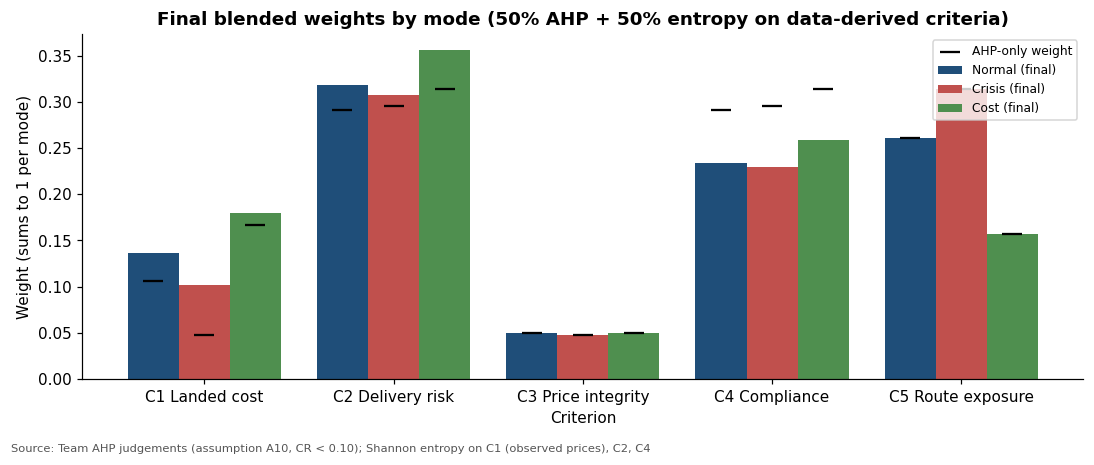

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
wt = weights_table.copy()
x = np.arange(len(CRITERIA))
for i, mode in enumerate(MODES):
    vals = wt[wt["mode"] == mode].set_index("criterion").loc[CRITERIA, "final"]
    ax.bar(x + (i - 1) * 0.27, vals, width=0.27, color=PALETTE[i], label=f"{mode.capitalize()} (final)")
    ahp_vals = wt[wt["mode"] == mode].set_index("criterion").loc[CRITERIA, "ahp"]
    ax.scatter(x + (i - 1) * 0.27, ahp_vals, color="black", marker="_", s=180, zorder=3, label="AHP-only weight" if i == 0 else None)
ax.set_xticks(x, ["C1 Landed cost", "C2 Delivery risk", "C3 Price integrity", "C4 Compliance", "C5 Route exposure"])
ax.set_title("Final blended weights by mode (50% AHP + 50% entropy on data-derived criteria)")
ax.set_xlabel("Criterion")
ax.set_ylabel("Weight (sums to 1 per mode)")
ax.legend(loc="upper right", fontsize=8)
save_fig(fig, "fig_12_final_weights_by_mode", "Team AHP judgements (assumption A10, CR < 0.10); Shannon entropy on C1 (observed prices), C2, C4")
plt.show()

**Business interpretation.** The black marks show the AHP-only weights; the bars show the final blend. Blending moves weight from compliance to delivery risk and cost, because delivery risk and price differ more between makers than the compliance scores do. The mode effect on route exposure (0.157 to 0.314) survives the blend.

### 4.3 TOPSIS ranking per mode (Build step 7)

**Section intro.** Each column is vector-normalised (a zero column stays zero), weighted, and compared with the ideal best (lowest value per criterion) and ideal worst (highest). Closeness S = distance to worst / (distance to best + distance to worst). Higher S is better; composite risk = 1 - S. We also compute AHP-only rankings to check whether blending mutes the effect of a mode switch (Phase 0 fix F7).

In [9]:
def matrix_for(mode):
    c5 = d["C5_crisis"] if mode == "crisis" else d["C5_normal"]
    return np.column_stack([d["C1"], d["C2"], d["C3"], d["C4"], c5])

rank = pd.DataFrame(index=d.index)
for mode in MODES:
    X = matrix_for(mode)
    rank[f"S_{mode}"] = topsis(X, [final[mode][c] for c in CRITERIA])
    rank[f"S_ahp_only_{mode}"] = topsis(X, [ahp_out[mode]["weights"][c] for c in CRITERIA])
    rank[f"rank_{mode}"] = rank[f"S_{mode}"].rank(ascending=False, method="min").astype(int)
    rank[f"rank_ahp_only_{mode}"] = rank[f"S_ahp_only_{mode}"].rank(ascending=False, method="min").astype(int)
rank["is_probation"] = d["is_probation"]
rank = rank.sort_values("rank_normal")
rank[["is_probation", "S_normal", "rank_normal", "S_crisis", "rank_crisis", "S_cost", "rank_cost", "rank_ahp_only_normal", "rank_ahp_only_crisis"]].round(4)

,is_probation,S_normal,rank_normal,S_crisis,rank_crisis,S_cost,rank_cost,rank_ahp_only_normal,rank_ahp_only_crisis
manufacturer_id,,,,,,,,,
AVYXA,True,0.8290,1,0.8434,1,0.8205,1,1,1
TEVA,False,0.8096,2,0.8030,2,0.8179,2,3,3
HOSPIRA,False,0.7637,3,0.7962,3,0.7419,4,2,2
GLAND,True,0.7439,4,0.7188,4,0.7525,3,4,4
FRESENIUS,False,0.7091,5,0.7019,5,0.7171,5,7,6
TEYRO,True,0.6544,6,0.6328,6,0.6644,6,5,5
BPI,True,0.6346,7,0.6114,7,0.6461,7,6,7
ACCORD,False,0.6045,8,0.5650,9,0.6310,8,9,10
NATCO,True,0.5912,9,0.5668,8,0.6049,9,8,9


**Business interpretation.** In Normal mode AVYXA ranks first (S 0.829), then Teva (0.810), Hospira (0.764) and Gland (0.744); Eugia is last (0.210), driven by the highest delivery risk and the second-highest compliance risk. The top of the list is mostly probation makers with little evidence, which is exactly why probation makers can only receive a capped trial share. Mode changes move the middle of the list: in Crisis, India-made Accord drops from 8th to 9th; in Cost focus, Gland and Hospira swap. Under AHP-only weights Hospira would rank above Teva in Normal and Crisis mode, so blending in the data mutes the board's preference for Hospira (Phase 0 fix F7). Both versions are exported so the dashboard can show the difference.

Saved figures\fig_13_topsis_by_mode.png


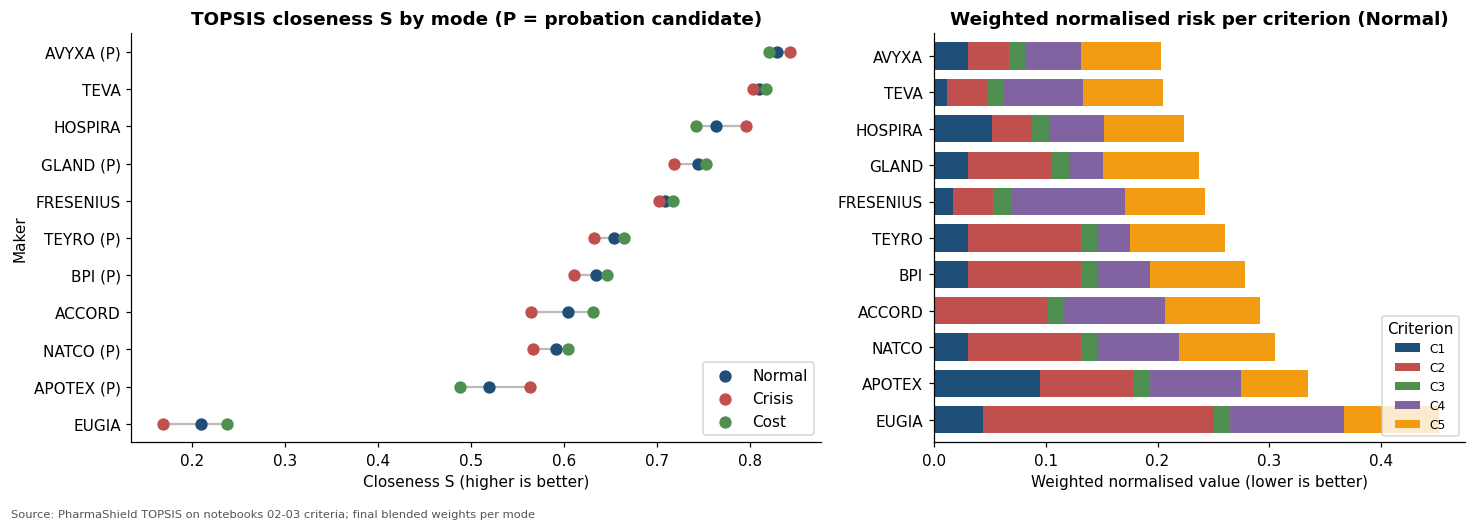

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
order = rank.index[::-1]
y = np.arange(len(order))
for i, mode in enumerate(MODES):
    axes[0].scatter(rank.loc[order, f"S_{mode}"], y, color=PALETTE[i], s=50, label=mode.capitalize(), zorder=3)
axes[0].hlines(y, rank.loc[order, [f"S_{m}" for m in MODES]].min(axis=1), rank.loc[order, [f"S_{m}" for m in MODES]].max(axis=1), color="#bbbbbb")
axes[0].set_yticks(y, [f"{m} (P)" if rank.loc[m, "is_probation"] else m for m in order])
axes[0].set_title("TOPSIS closeness S by mode (P = probation candidate)")
axes[0].set_xlabel("Closeness S (higher is better)")
axes[0].set_ylabel("Maker")
axes[0].legend(loc="lower right")
Xn = pd.DataFrame(matrix_for("normal"), index=d.index, columns=CRITERIA)
contrib = pd.DataFrame({c: final["normal"][c] * Xn.loc[rank.index, c] / np.sqrt((Xn[c] ** 2).sum()) for c in CRITERIA}, index=rank.index)
contrib.loc[order].plot(kind="barh", stacked=True, ax=axes[1], color=PALETTE[:5], width=0.75)
axes[1].set_title("Weighted normalised risk per criterion (Normal)")
axes[1].set_xlabel("Weighted normalised value (lower is better)")
axes[1].set_ylabel("")
axes[1].legend(title="Criterion", fontsize=8, loc="lower right")
save_fig(fig, "fig_13_topsis_by_mode", "PharmaShield TOPSIS on notebooks 02-03 criteria; final blended weights per mode")
plt.show()

**Business interpretation.** The left chart shows how little some makers move between modes and how much others do. The right chart explains each Normal-mode position: Eugia's long bar is delivery risk plus compliance, Accord's is compliance, Apotex's is cost. A category manager can see in one glance which weakness would need to be fixed for a maker to move up.

### 4.4 MILP order split per mode (Build step 8)

**Section intro.** The order split is a mixed-integer linear program because binary variables y_i decide whether maker i is in the portfolio:
- Minimise the sum of (landed cost_i + lambda x mean landed cost x (1 - S_i)) x vials_i + 1,000,000 x spot-buy vials.
- Demand: vials from all makers + spot buy = 10,000.
- Capacity: vials_i <= capacity_i x y_i (assumptions A27, A28).
- Tier 1 concentration: an established maker gets at most 70% of demand; if selected, at least 10% (a warm backup, assumption A30).
- Dual sourcing: at least 2 established makers selected.
- Probation: at most 2 trial makers; if selected, 5% to 15% of demand (30% if fewer than 2 established makers exist); a maker failing the safety gate cannot be selected (A13); at least one eligible trial maker per order (A29).
- Spot buy: an emergency slack that the large penalty keeps at zero unless capacity runs out.
- Tie-break: a negligible term of 0.001 USD x (1 - S) per vial makes the higher-ranked maker win when landed costs are identical (the five imputed prices). It changes the monthly cost by at most 10 USD, and it makes the Python (CBC) and browser (JavaScript) solvers return the same split.

In [11]:
alloc, summary = {}, {}
for mode in MODES:
    inp = pd.DataFrame({"landed_cost": lc, "S": rank[f"S_{mode}"], "is_probation": d["is_probation"],
                        "trial_gate_pass": d["trial_gate_pass"], "capacity": d["monthly_capacity_units"]})
    a, s = allocate_milp(inp, DEMAND, lam=LAMBDA)
    assert s["status"] == "Optimal", s
    assert a["vials"].sum() + s["spot_buy_vials"] == DEMAND
    alloc[mode], summary[mode] = a, s
split = pd.concat({m: alloc[m].loc[alloc[m]["vials"] > 0, ["role", "vials", "share"]] for m in MODES})
split

role  vials  share
normal ACCORD           backup   2500   0.25
       AVYXA   probation trial    500   0.05
       TEVA            primary   7000   0.70
crisis ACCORD           backup   2500   0.25
       AVYXA   probation trial    500   0.05
       TEVA            primary   7000   0.70
cost   ACCORD           backup   2500   0.25
       AVYXA   probation trial    500   0.05
       TEVA            primary   7000   0.70

**Business interpretation.** At lambda 1.0 the MILP finds an optimal split in all three modes: Teva 7,000 vials as primary (70%, the Tier 1 cap), Accord 2,500 as warm backup (25%) and AVYXA 500 as a probation trial (5%). No spot buy is needed. The split is the same in every mode at this lambda because Accord is 17% cheaper per vial than Teva and 24% cheaper than Fresenius Kabi, which outweighs its higher risk at this price of risk.

In [12]:
def kpis(mode):
    a = alloc[mode]
    v = a["vials"]
    c5 = d["C5_crisis"] if mode == "crisis" else d["C5_normal"]
    return {"purchase_cost_usd": float((v * lc).sum()), "cost_per_vial_usd": float((v * lc).sum() / DEMAND),
            "expected_late_share": float((v * d["C2"]).sum() / DEMAND), "route_exposure_weighted": float((v * c5).sum() / DEMAND),
            "india_made_share": float(v[d["manufacturing_country"].eq("India")].sum() / DEMAND),
            "primary_share": float(a["share"].max()), "suppliers_used": int((v > 0).sum()),
            "probation_trial_share": float(a.loc[a["role"].eq("probation trial"), "share"].sum()),
            "warm_backup_share": float(a.loc[a["role"].eq("backup"), "share"].sum()),
            "spot_buy_vials": summary[mode]["spot_buy_vials"]}
kpi = pd.DataFrame({m: kpis(m) for m in MODES}).astype(float)
pd.set_option("display.float_format", "{:,.4f}".format)
cheapest_single = float(lc[~d["is_probation"]].min() * DEMAND)
print(f"Reference: buying all 10,000 vials from the cheapest established maker would cost {cheapest_single:,.0f} USD but breaks the Tier 1 rules (70% cap, dual sourcing).")
kpi.round(4)

Reference: buying all 10,000 vials from the cheapest established maker would cost 1,223,758 USD but breaks the Tier 1 rules (70% cap, dual sourcing).


,normal,crisis,cost
purchase_cost_usd,"1,435,069.4328","1,435,069.4328","1,435,069.4328"
cost_per_vial_usd,143.5069,143.5069,143.5069
expected_late_share,0.0231,0.0231,0.0231
route_exposure_weighted,0.2390,0.2600,0.2390
india_made_share,0.2500,0.2500,0.2500
primary_share,0.7000,0.7000,0.7000
suppliers_used,3.0000,3.0000,3.0000
probation_trial_share,0.0500,0.0500,0.0500
warm_backup_share,0.2500,0.2500,0.2500
spot_buy_vials,0.0000,0.0000,0.0000


**Business interpretation.** The recommended split costs 1,435,069 USD a month (143.51 USD per vial). That is 211,311 USD (17.3%) more than putting everything on Accord, the cheapest established maker, which would break the Tier 1 rules. The premium buys a primary with lower delivery risk (expected late share 2.31% for the portfolio) and a guaranteed warm backup. In Crisis mode the same split carries a higher route exposure (0.260 against 0.239), which tells the board the portfolio is more exposed than in peacetime even though the volumes have not moved.

Saved figures\fig_14_milp_split_by_mode.png


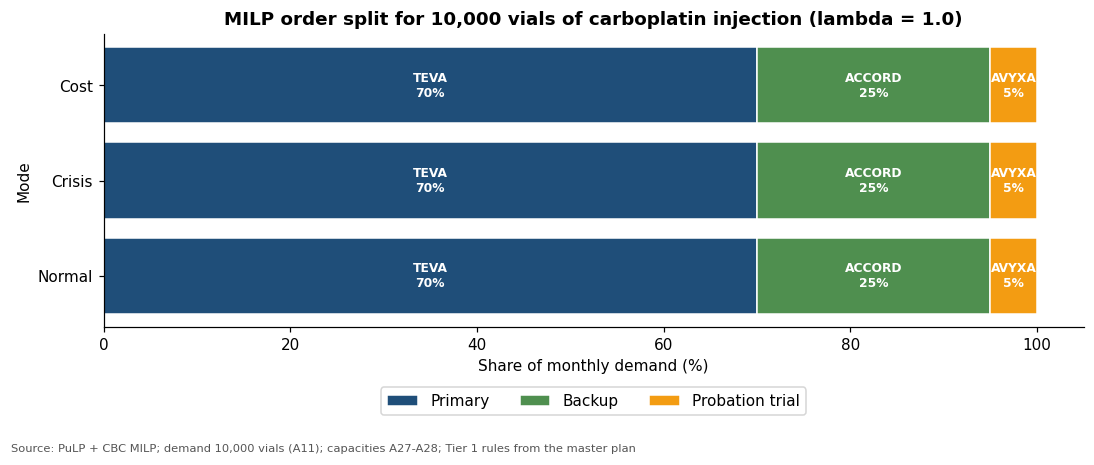

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
role_colors = {"primary": PALETTE[0], "backup": PALETTE[2], "probation trial": PALETTE[4]}
left = np.zeros(len(MODES))
labels_done = set()
for i, mode in enumerate(MODES):
    a = alloc[mode].query("vials > 0").sort_values("vials", ascending=False)
    start = 0
    for m, r in a.iterrows():
        ax.barh(i, r["share"] * 100, left=start, color=role_colors[r["role"]], edgecolor="white",
                label=r["role"].capitalize() if r["role"] not in labels_done else None)
        labels_done.add(r["role"])
        ax.text(start + r["share"] * 50, i, f"{m}\n{r['share']:.0%}", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
        start += r["share"] * 100
ax.set_yticks(range(len(MODES)), [m.capitalize() for m in MODES])
ax.set_title(f"MILP order split for {DEMAND:,} vials of carboplatin injection (lambda = {LAMBDA})")
ax.set_xlabel("Share of monthly demand (%)")
ax.set_ylabel("Mode")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
save_fig(fig, "fig_14_milp_split_by_mode", "PuLP + CBC MILP; demand 10,000 vials (A11); capacities A27-A28; Tier 1 rules from the master plan")
plt.show()

**Business interpretation.** All three modes produce the same 70/25/5 split at lambda 1.0, which is itself a finding: the recommendation is stable across board priorities at the default price of risk. The next cell shows the lambda value at which a crisis changes the split.

### 4.5 Lambda sensitivity (override 5)

**Section intro.** Lambda is the price the board puts on risk, in units of the average landed cost. Lambda 0 means "buy on price only"; a high lambda means "pay more for lower risk". We re-solve the MILP for Normal and Crisis over a range of lambda values.

In [14]:
LAMBDAS = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]
sens_rows = []
for mode in ["normal", "crisis"]:
    for lam in LAMBDAS:
        inp = pd.DataFrame({"landed_cost": lc, "S": rank[f"S_{mode}"], "is_probation": d["is_probation"],
                            "trial_gate_pass": d["trial_gate_pass"], "capacity": d["monthly_capacity_units"]})
        a, s = allocate_milp(inp, DEMAND, lam=lam)
        used = a[a["vials"] > 0].sort_values("vials", ascending=False)
        c5 = d["C5_crisis"] if mode == "crisis" else d["C5_normal"]
        sens_rows.append({"mode": mode, "lambda": lam, "split": ", ".join(f"{m} {v:,}" for m, v in used["vials"].items()),
                          "purchase_cost_usd": s["purchase_cost_usd"], "expected_late_share": float((a["vials"] * d["C2"]).sum() / DEMAND),
                          "india_made_share": float(a.loc[d["manufacturing_country"].eq("India"), "vials"].sum() / DEMAND),
                          "route_exposure_weighted": float((a["vials"] * c5).sum() / DEMAND)})
sens = pd.DataFrame(sens_rows)
sens

,mode,lambda,split,purchase_cost_usd,expected_late_share,india_made_share,route_exposure_weighted
0,normal,0.0000,"ACCORD 7,000, TEVA 2,500, GLAND 500","1,320,285.4033",0.0370,0.7500,0.2610
1,normal,0.5000,"ACCORD 7,000, TEVA 2,500, AVYXA 500","1,320,939.5011",0.0362,0.7000,0.2588
2,normal,1.0000,"TEVA 7,000, ACCORD 2,500, AVYXA 500","1,435,069.4328",0.0231,0.2500,0.2390
3,normal,1.5000,"TEVA 7,000, ACCORD 2,500, AVYXA 500","1,435,069.4328",0.0231,0.2500,0.2390
4,normal,2.0000,"TEVA 7,000, AVYXA 1,500, FRESENIUS 1,500","1,559,745.3153",0.0159,0.0000,0.2280
5,normal,3.0000,"TEVA 7,000, AVYXA 1,500, FRESENIUS 1,500","1,559,745.3153",0.0159,0.0000,0.2280
6,normal,5.0000,"TEVA 7,000, AVYXA 1,500, FRESENIUS 1,000, GLAND 500","1,573,825.7842",0.0168,0.0500,0.2302
7,crisis,0.0000,"ACCORD 7,000, TEVA 2,500, GLAND 500","1,320,285.4033",0.0370,0.7500,0.3000
8,crisis,0.5000,"ACCORD 7,000, TEVA 2,500, AVYXA 500","1,320,939.5011",0.0362,0.7000,0.2960
9,crisis,1.0000,"TEVA 7,000, ACCORD 2,500, AVYXA 500","1,435,069.4328",0.0231,0.2500,0.2600


**Business interpretation.** Lambda is the real lever. At lambda 0 (price only) the MILP puts Accord as primary (70%) and the India-made share is 75%. At the default lambda 1.0, Teva becomes primary and the India-made share falls to 25%. In Crisis mode, raising lambda to 1.5 replaces India-made Accord with US-made Fresenius Kabi as backup and lifts the AVYXA trial to 15%: India-made share falls from 25% to 0% and expected late share from 2.31% to 1.59%, for 124,676 USD more per month (+8.7%). In Normal mode the same change needs lambda 2.0. In a Hormuz crisis, then, the board needs only a moderate increase in risk appetite to move volume off the more exposed lanes.

Saved figures\fig_15_lambda_sensitivity.png


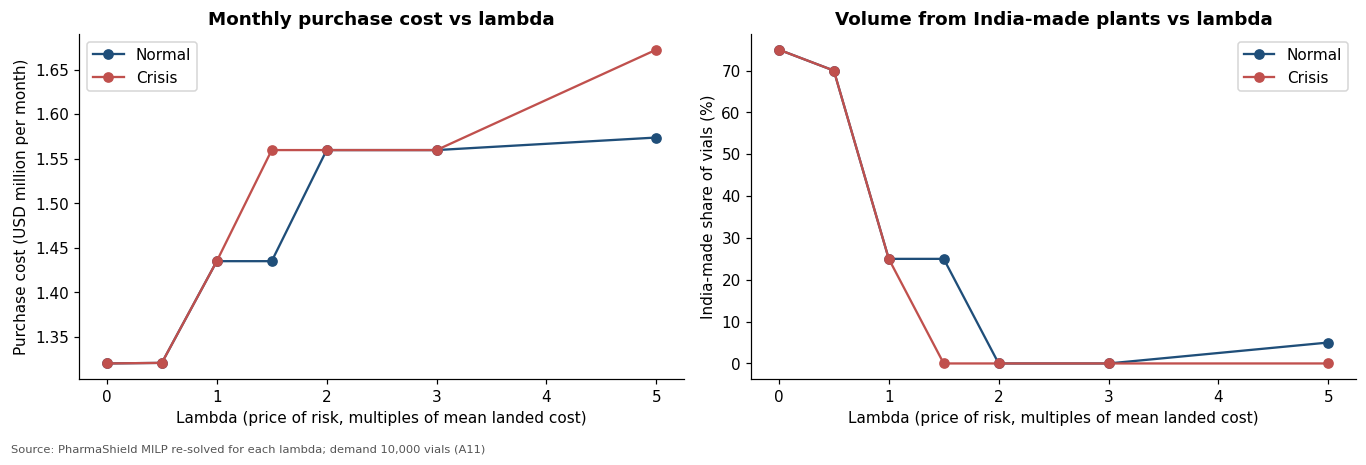

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for i, mode in enumerate(["normal", "crisis"]):
    s = sens[sens["mode"] == mode]
    axes[0].plot(s["lambda"], s["purchase_cost_usd"] / 1e6, marker="o", color=PALETTE[i], label=mode.capitalize())
    axes[1].plot(s["lambda"], s["india_made_share"] * 100, marker="o", color=PALETTE[i], label=mode.capitalize())
axes[0].set_title("Monthly purchase cost vs lambda")
axes[0].set_xlabel("Lambda (price of risk, multiples of mean landed cost)")
axes[0].set_ylabel("Purchase cost (USD million per month)")
axes[0].legend()
axes[1].set_title("Volume from India-made plants vs lambda")
axes[1].set_xlabel("Lambda (price of risk, multiples of mean landed cost)")
axes[1].set_ylabel("India-made share of vials (%)")
axes[1].legend()
save_fig(fig, "fig_15_lambda_sensitivity", "PharmaShield MILP re-solved for each lambda; demand 10,000 vials (A11)")
plt.show()

**Business interpretation.** Cost rises in steps, not smoothly, because the binary choices switch whole suppliers in and out. The India-made share drops to zero at lambda 1.5 in Crisis mode but only at 2.0 in Normal mode. This chart is the board's trade-off: each step to the right buys lower delivery and route risk for a known monthly cost.

**Section summary.** Weights pass the consistency test, the ranking reacts to the mode, and the MILP returns an optimal Tier 1 compliant split in every mode. Lambda is the lever that decides how much of that ranking turns into volume.

## 5. Evaluation

**Section intro.** Two robustness checks. First, a CRITIC cross-check of the objective weights (Phase 0 fix F8): CRITIC uses contrast and correlation instead of entropy. Second, a Monte Carlo test: 1,000 random perturbations of the final Normal weights (each weight multiplied by a uniform factor between 0.8 and 1.2, then renormalised, seed 42), counting how often the top-ranked established maker stays first among established makers.

In [16]:
dc = pd.DataFrame({"C1": d.loc[~d["c1_imputed"], "C1"], "C2": d.loc[~d["c1_imputed"], "C2"], "C4": d.loc[~d["c1_imputed"], "C4"]})
std = dc.std(ddof=0) / (dc.max() - dc.min())
corr = dc.corr()
info = std * (1 - corr).sum()
critic = info / info.sum()
print("CRITIC weights on observed-price makers (n = 6):", critic.round(4).to_dict())
print("Entropy weights (data-only):", {k: round(float(v), 4) for k, v in ent_w.items()})

est = d.index[~d["is_probation"]]
base_top = rank.loc[est, "S_normal"].idxmax()
X = matrix_for("normal")
base_w = np.array([final["normal"][c] for c in CRITERIA])
hits, top_counts = 0, {}
for _ in range(1000):
    w = base_w * rng.uniform(0.8, 1.2, size=5)
    w = w / w.sum()
    s = pd.Series(topsis(X, w), index=d.index)
    top = s[est].idxmax()
    top_counts[top] = top_counts.get(top, 0) + 1
    hits += top == base_top
print(f"Top established maker under base weights: {base_top}; stays first in {hits / 10:.1f}% of 1,000 perturbations")
print("Top established maker counts:", top_counts)

CRITIC weights on observed-price makers (n = 6): {'C1': 0.3972, 'C2': 0.2679, 'C4': 0.3349}
Entropy weights (data-only): {'C1': 0.2433, 'C2': 0.5009, 'C4': 0.2558}


Top established maker under base weights: TEVA; stays first in 98.3% of 1,000 perturbations
Top established maker counts: {'TEVA': 983, 'HOSPIRA': 17}


**Business interpretation.** CRITIC, a second objective method, gives C1 0.397, C2 0.268 and C4 0.335 on the six makers with observed prices. It agrees that all three data criteria matter but puts more weight on cost than entropy does. Because objective methods disagree, the board's AHP half anchors the final weights. In the Monte Carlo test, Teva stays the top established maker in 983 of 1,000 random weight changes of up to 20% (98.3%); Hospira takes first place in the other 17. The primary-supplier recommendation is robust.

### 5.1 Save the locked schema and the web exports

**Section intro.** `suppliers_matrix.csv` follows the locked schema in the master plan (section 5.1) plus agreed extra columns: the raw landed cost, the imputation and evidence status flags, the Crisis C5 value and the trial gate. Rankings and allocations are saved per mode in outputs/, and compact JSON files for the web app in web/data/.

In [17]:
locked = pd.DataFrame({
    "sku_id": SKU_ID, "criticality_tier": 1, "manufacturer_id": d.index, "labeler_name_fda": d["labeler_name_fda"],
    "manufacturing_country": d["manufacturing_country"], "is_probation": d["is_probation"], "monthly_capacity_units": d["monthly_capacity_units"],
    "C1_landed_cost": d["C1"], "C2_delivery_risk": d["C2"], "C3_price_integrity": d["C3"], "C4_compliance_risk": d["C4"],
    "C5_route_exposure": d["C5_normal"], "hormuz_air_share": d["hormuz_air_share"], "active_fda_shortage": d["active_fda_shortage"],
    "oai_count_5yr": d["oai_count_5yr"], "shap_top3_reasons": d["shap_top3_reasons"],
    # agreed extra columns
    "parent_group": d["parent_group"], "landed_cost_usd_per_vial": lc, "c1_imputed": d["c1_imputed"], "c3_status": d["c3_status"],
    "c4_evidence_status": d["c4_evidence_status"], "nlp_status": d["nlp_status"], "C5_route_exposure_crisis": d["C5_crisis"],
    "trial_gate_pass": d["trial_gate_pass"], "unit_share_2025": d["unit_share_2025"]}).reset_index(drop=True)
locked.to_csv(PROCESSED / "suppliers_matrix.csv", index=False)
shape("Saved data/processed/suppliers_matrix.csv", locked)
for mode in MODES:
    r = rank[[f"S_{mode}", f"rank_{mode}", f"S_ahp_only_{mode}", "is_probation"]].rename(columns={f"S_{mode}": "S", f"rank_{mode}": "rank", f"S_ahp_only_{mode}": "S_ahp_only"})
    r["composite_risk"] = 1 - r["S"]
    r.sort_values("rank").to_csv(OUTPUTS / f"topsis_ranking_carboplatin_{mode}.csv")
    alloc[mode].to_csv(OUTPUTS / f"lp_allocation_carboplatin_{mode}.csv")
print("Saved outputs/topsis_ranking_carboplatin_<mode>.csv and outputs/lp_allocation_carboplatin_<mode>.csv for", MODES)

Saved data/processed/suppliers_matrix.csv: 11 rows x 25 columns
Saved outputs/topsis_ranking_carboplatin_<mode>.csv and outputs/lp_allocation_carboplatin_<mode>.csv for ['normal', 'crisis', 'cost']


**Business interpretation.** The locked-schema table (11 makers, 16 locked columns plus 9 agreed extras) and the per-mode ranking and allocation files are saved. These are the files the team's slides and any spreadsheet checks should cite.

In [18]:
makers_json = []
for m, r in d.iterrows():
    makers_json.append({
        "id": m, "name": r["labeler_name_fda"], "parent": r["parent_group"], "country": r["manufacturing_country"],
        "is_probation": bool(r["is_probation"]), "trial_gate_pass": bool(r["trial_gate_pass"]), "c1_imputed": bool(r["c1_imputed"]),
        "landed_cost": r["landed_cost_per_vial_usd"], "price_per_ml": r["price_per_ml_usd"], "unit_share_2025": r["unit_share_2025"],
        "capacity": int(r["monthly_capacity_units"]), "active_fda_shortage": bool(r["active_fda_shortage"]),
        "current_shortage_records": int(r["current_shortage_records"]), "oai_count_5yr": int(r["oai_count_5yr"]), "vai_count_5yr": int(r["vai_count_5yr"]),
        "inspections_5yr": int(r["inspections_5yr"]), "class_i_ii_5yr": int(r["class_i_ii_5yr"]), "class_i_5yr": int(r["class_i_5yr"]),
        "nlp_citations_5yr": int(r["nlp_citations_5yr"]), "nlp_severity": r["nlp_severity"], "nlp_status": r["nlp_status"],
        "c3_status": r["c3_status"], "c3_lines_scored": int(r["c3_lines_scored"]), "c4_evidence_status": r["c4_evidence_status"],
        "scms_lines": int(r["scms_lines"]), "site_prior_source": r["site_prior_source"], "hormuz_air_share": r["hormuz_air_share"], "lpi": r["lpi_2023"],
        "criteria": {"C1": r["C1"], "C2": r["C2"], "C3": r["C3"], "C4": r["C4"], "C5_normal": r["C5_normal"], "C5_crisis": r["C5_crisis"]},
        "shap_top3": json.loads(r["shap_top3_reasons"])})
export.write("suppliers.json", {"sku_id": SKU_ID, "sku_label": "Carboplatin injection 10 mg/mL (45 mL vial)", "tier": TIER, "demand": DEMAND,
                                "lambda_default": LAMBDA, "data_criteria": DATA_CRITERIA, "entropy_inputs": {"C1": "landed_cost of makers with c1_imputed false", "C2": "criteria.C2", "C4": "criteria.C4"},
                                "makers": makers_json})
normal_rank = rank["rank_normal"]
for mode in MODES:
    export.write(f"weights_{mode}.json", {"mode": mode, "ahp_matrix": AHP_MATRICES[mode], "ahp_weights": ahp_out[mode]["weights"],
        "lambda_max": ahp_out[mode]["lambda_max"], "ci": ahp_out[mode]["ci"], "cr": ahp_out[mode]["cr"], "entropy_weights": ent_w,
        "entropy_divergence": ent_div, "data_criteria": DATA_CRITERIA, "final_weights": final[mode], "plan_target": dict(zip(CRITERIA, PLAN_TARGET[mode])),
        "c5_column": "C5_crisis" if mode == "crisis" else "C5_normal"})
    export.write(f"rankings_{mode}.json", {"mode": mode, "rows": [{"id": m, "S": rank.loc[m, f"S_{mode}"], "composite_risk": 1 - rank.loc[m, f"S_{mode}"],
        "rank": int(rank.loc[m, f"rank_{mode}"]), "rank_normal": int(normal_rank[m]), "rank_change_vs_normal": int(normal_rank[m] - rank.loc[m, f"rank_{mode}"]),
        "S_ahp_only": rank.loc[m, f"S_ahp_only_{mode}"]} for m in rank.sort_values(f"rank_{mode}").index]})
    a = alloc[mode]
    export.write(f"allocations_{mode}.json", {"mode": mode, "demand": DEMAND, "lambda": LAMBDA, "status": summary[mode]["status"],
        "objective": summary[mode]["objective"], "spot_buy_vials": summary[mode]["spot_buy_vials"], "kpis": kpis(mode),
        "rows": [{"id": m, "vials": int(a.loc[m, "vials"]), "share": a.loc[m, "share"], "role": a.loc[m, "role"],
                  "unit_objective_cost": a.loc[m, "unit_objective_cost"]} for m in a.sort_values("vials", ascending=False).index],
        "lambda_sensitivity": sens[sens["mode"] == mode].drop(columns="mode").to_dict(orient="records") if mode != "cost" else []})
shap_doc = export.processed_json("shap_summary.json")
export.write("shap.json", shap_doc)
metrics_doc = export.processed_json("model_metrics.json")
metrics_doc["c3"]["examples"] = export.processed_json("iforest_anomalies.json")["examples"]
metrics_doc["robustness"] = {"critic_weights": critic.to_dict(), "monte_carlo_runs": 1000, "base_top_established": base_top, "stays_top_share": hits / 1000,
                             "top_counts": top_counts}
export.write("model_metrics.json", metrics_doc)
export.write("nlp_letters.json", export.processed_json("nlp_summary.json"))
export.write("contract_clauses.json", export.processed_json("contract_clauses.json"))
export.write("shortages_cache.json", export.shortages_cache())
export.write("meta.json", export.meta({"sku_id": SKU_ID, "demand": DEMAND, "lambda_default": LAMBDA, "modes": MODES, "makers": len(d),
    "notebooks": ["01_scms_eda_cleaning", "02_scoring_panel_2026", "03_risk_models_xgb_iforest_nlp", "04_mcdm_topsis_milp"]}))
written = sorted(p.name for p in export.WEB_DATA.glob("*.json"))
print(f"Wrote {len(written)} JSON files to web/data:", written)

Wrote 16 JSON files to web/data: ['allocations_cost.json', 'allocations_crisis.json', 'allocations_normal.json', 'contract_clauses.json', 'meta.json', 'model_metrics.json', 'nlp_letters.json', 'rankings_cost.json', 'rankings_crisis.json', 'rankings_normal.json', 'shap.json', 'shortages_cache.json', 'suppliers.json', 'weights_cost.json', 'weights_crisis.json', 'weights_normal.json']


**Business interpretation.** Sixteen JSON files now feed the web app: supplier profiles, weights, rankings and allocations for each mode, model evidence, NLP and contract outputs, the shortage cache and run metadata. Every number on the dashboard is traceable to this run.

**Section summary.** The ranking and split are robust to reasonable weight changes, and every output the web app shows is exported from this run, so the dashboard and the deck read the same numbers.

## 6. Conclusion

**Recommendation for the GPO (carboplatin injection, Tier 1, 10,000 vials a month).**
- Split the order 70/25/5: Teva Parenteral Medicines as primary (7,000 vials), Accord as warm backup (2,500) and AVYXA as a probation trial (500). This costs 1,435,069 USD a month and meets every Tier 1 rule.
- In a Hormuz or Gulf airspace crisis, raise lambda to 1.5. The backup moves from India-made Accord to US-made Fresenius Kabi and the trial to 15%. India-made volume falls from 25% to 0% for 8.7% more cost.
- A human category manager approves every split (dashboard Approval page). No order is sent automatically.

**Why it can be trusted.**
- AHP consistency ratios are below 0.005.
- Entropy is applied only to real data.
- The primary choice survives 98.3% of random weight changes.
- Every imputed or neutral value is flagged.

**Limits.**
- Demand, capacities and the route mix are scenario assumptions (A8, A11, A27, A28).
- Prices are a US Medicaid proxy (A4).
- The ranking's top places include probation makers with thin evidence. The MILP limits their volume, but their scores should be read as provisional.

**Future improvements.**
- Calibrate lambda with the board using past stock-out costs.
- Replace assumed capacities with supplier-confirmed allocations.
- Add a multi-period model that tracks safety stock.
- Re-run monthly as the openFDA and FDA feeds refresh.

**End of notebook 04.** The web app in web/ reads the JSON files exported above. Re-run everything with `python pipeline/run_all.py`.